DSC540-T301 <br>
Week 7&8 Assignment<br>
Jeremy Barton <br>

For the cleaning part of this exercise, we'll deal mostly with the Candy data from <a href="https://www.scq.ubc.ca/so-much-candy-data-seriously/">"So Much Candy Data, Seriously"</a>. When it comes to formatting, the MetObjects CSV file will be transformed to begin the kinds cleaning techniques made on the Candy dataset. 

In [1]:
import pandas as pd
import numpy as np

# Pull in Candy data
candy_df = pd.read_excel("wk_7-8_data/CANDYDATA.xlsx")
# Pull in MetObjects CSV
met_df = pd.read_csv("wk_7-8_data/MetObjects.csv", encoding='latin1')

/home/jeremy/Documents/GitHub/DSC540/env/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


<b>So Much Candy Data, Seriously</b>

Here's what the candy data looks like. It is already formatted corretly to begin the cleaning process. First we will check for any missing or duplicated data, as covered in Chapter 7, but not before a quick `.dtypes` check.

In [2]:
candy_df.dtypes

ITEM              object
JOY                int64
DESPAIR            int64
NET FEELIES      float64
NET CLOUT        float64
DESPAIR (NEG)    float64
dtype: object

Before immediately removing all NA and missing values, it is good practice to investigate them to understand where and how many exist. It does appear from the analysis below that there is exactly <b>one</b> NA value in three of the six columns.

In [3]:
candy_df.isna().sum()

ITEM             1
JOY              0
DESPAIR          0
NET FEELIES      1
NET CLOUT        1
DESPAIR (NEG)    1
dtype: int64

Being that the idea of this dataset is to measure emotions, to use the wrong filling method will certainly result in skewing the data. For example, setting all NA values to 0 and leaving them alone will cause their rows to be misrepresented entirely instead of having an estimation of that value based on known filling techniques.

To solve this, NAs will be filled with the `.mean()` of that field.

#### Chapter 7, Exercise 2: Fill in mising data

In [4]:
# IMPORTANT: Ensure proper use of paraenthesis and brackets.
candy_df["JOY"] = candy_df["JOY"].fillna(candy_df["JOY"].mean())
                # Fill NA values in the "JOY" field
                #   with the .mean() of the cand_df["JOY"] field

candy_df["DESPAIR"] = candy_df["DESPAIR"].fillna(candy_df["DESPAIR"].mean())
candy_df["NET FEELIES"] = candy_df["NET FEELIES"].fillna(candy_df["NET FEELIES"].mean())
candy_df["NET CLOUT"] = candy_df["NET CLOUT"].fillna(candy_df["NET CLOUT"].mean())
candy_df["DESPAIR (NEG)"] = candy_df["DESPAIR (NEG)"].fillna(candy_df["DESPAIR (NEG)"].mean())

ITEM has an NA value. This can be dropped entirely.

In [5]:
candy_df["ITEM"] = candy_df["ITEM"].dropna

Now there are no missing values.

In [6]:
candy_df.isna().sum()

ITEM             0
JOY              0
DESPAIR          0
NET FEELIES      0
NET CLOUT        0
DESPAIR (NEG)    0
dtype: int64

In pandas, the `.duplicate()` function can be used to locate duplicates in a dataset. It doesn't appear there are any in the Candy dataset though.

In [7]:
candy_df.duplicated().any()

np.False_

Pivoting the data will help allow multi-level comparisons between fields and values. The Candy hiearchy data is perfect for this transformation due to it's numerous categorical fields.

To get there though, the data will need to be cleaned. Plenty of NA values exist in the `candyniearchy2017.xlsx` dataset, so removing them is once again not an option.

Instead, they will be replaced with "NO DATA" to make it known that no information was collected for this response.

In [8]:
hcandy_df = pd.read_excel("wk_7-8_data/candyhierarchy2017.xlsx")
hcandy_df.isna().sum()

/home/jeremy/Documents/GitHub/DSC540/env/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


Internal ID                    0
Q1: GOING OUT?               110
Q2: GENDER                    41
Q3: AGE                       84
Q4: COUNTRY                   64
                            ... 
Q12: MEDIA [Daily Dish]     2375
Q12: MEDIA [Science]        1098
Q12: MEDIA [ESPN]           2361
Q12: MEDIA [Yahoo]          2393
Click Coordinates (x, y)     855
Length: 120, dtype: int64

#### Chapter 7, Exercise 5: Replace values

This will be a simple `.replace()` to "NO DATA" on any values that are NaN.

In [9]:
hcandy_df = hcandy_df.fillna("NO DATA")

Now NaN values are filled with the specified string.

In [10]:
hcandy_df.head(1)

,Internal ID,Q1: GOING OUT?,Q2: GENDER,Q3: AGE,Q4: COUNTRY,"Q5: STATE, PROVINCE, COUNTY, ETC",Q6 | 100 Grand Bar,Q6 | Anonymous brown globs that come in black and orange wrappers\t(a.k.a. Mary Janes),Q6 | Any full-sized candy bar,Q6 | Black Jacks,...,Q8: DESPAIR OTHER,Q9: OTHER COMMENTS,Q10: DRESS,Unnamed: 113,Q11: DAY,Q12: MEDIA [Daily Dish],Q12: MEDIA [Science],Q12: MEDIA [ESPN],Q12: MEDIA [Yahoo],"Click Coordinates (x, y)"
0,90258773,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA,...,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA,NO DATA


Every participant in the survey had questions they did not answer. Removing them all would have taken out the entire dataset. This reinforces the idea that choosing a proper filling method greatly contributes to the required approach of an analysis.

From this point forward, we can pivot the dataframe.

#### Chapter 8, Exercise 3: Reshape the data

Taking a look a the shape, there are over 2,000 entries with 120 fields.

In [11]:
# Preprocessing
hcandy_df.columns = hcandy_df.columns.str.strip()
hcandy_df.shape

(2460, 120)

In [12]:
# Looking at the column headers
hcandy_df.columns.tolist()

['Internal ID',
 'Q1: GOING OUT?',
 'Q2: GENDER',
 'Q3: AGE',
 'Q4: COUNTRY',
 'Q5: STATE, PROVINCE, COUNTY, ETC',
 'Q6 | 100 Grand Bar',
 'Q6 | Anonymous brown globs that come in black and orange wrappers\t(a.k.a. Mary Janes)',
 'Q6 | Any full-sized candy bar',
 'Q6 | Black Jacks',
 'Q6 | Bonkers (the candy)',
 'Q6 | Bonkers (the board game)',
 'Q6 | Bottle Caps',
 "Q6 | Box'o'Raisins",
 'Q6 | Broken glow stick',
 'Q6 | Butterfinger',
 'Q6 | Cadbury Creme Eggs',
 'Q6 | Candy Corn',
 'Q6 | Candy that is clearly just the stuff given out for free at restaurants',
 'Q6 | Caramellos',
 'Q6 | Cash, or other forms of legal tender',
 'Q6 | Chardonnay',
 'Q6 | Chick-o-Sticks (we don’t know what that is)',
 'Q6 | Chiclets',
 'Q6 | Coffee Crisp',
 'Q6 | Creepy Religious comics/Chick Tracts',
 'Q6 | Dental paraphenalia',
 'Q6 | Dots',
 'Q6 | Dove Bars',
 'Q6 | Fuzzy Peaches',
 'Q6 | Generic Brand Acetaminophen',
 'Q6 | Glow sticks',
 'Q6 | Goo Goo Clusters',
 "Q6 | Good N' Plenty",
 'Q6 | Gum fro

For the sake of this analysis, the hiearchical candy data will be filtered to the countries United States and Canada, with only responses for Skittles, Nerds, Butterfingers and Starburst.

In [13]:
# Filter on just US and Canada and specific candy columns plus age
us_canada_df = hcandy_df[
    hcandy_df["Q4: COUNTRY"].isin(["United States", "Canada"])
][["Q4: COUNTRY", "Q3: AGE", "Q6 | Skittles", "Q6 | Nerds", "Q6 | Butterfinger", "Q6 | Twix", "Q6 | Starburst"]]

The data is now much smaller in shape due to the transformations for the pivot table.

In [14]:
us_canada_df.shape

(676, 7)

#### Chapter 8, Exercise 4: Pivot the data

This pivot table analysis will show the number of answers for Stittles, Butterfinger, Twix and Starburst by Age and Counry. To narrow down the results, only United States and Canada are included.

In [15]:


# Counting # of answers by country, age, gender
us_canada_df.pivot_table(
    index=None,
    columns=["Q3: AGE", "Q4: COUNTRY"],
    values=["Q6 | Skittles", "Q6 | Nerds", "Q6 | Butterfinger", "Q6 | Twix", "Q6 | Starburst"],
    aggfunc="count"
)

Q3: AGE                       6             8      9     10            11  \
Q4: COUNTRY       United States United States Canada Canada United States   
Q6 | Butterfinger             1             1      1      1             1   
Q6 | Nerds                    1             1      1      1             1   
Q6 | Skittles                 1             1      1      1             1   
Q6 | Starburst                1             1      1      1             1   
Q6 | Twix                     1             1      1      1             1   

Q3: AGE               13            15            16     17     18  ...  \
Q4: COUNTRY       Canada United States United States Canada Canada  ...   
Q6 | Butterfinger      1             2             2      2      2  ...   
Q6 | Nerds             1             2             2      2      2  ...   
Q6 | Skittles          1             2             2      2      2  ...   
Q6 | Starburst         1             2             2      2      2  ...   
Q6 | Twix              1             2             2      2      2  ...   

Q3: AGE                      67            68            70            71  \
Q4: COUNTRY       United States United States United States United States   
Q6 | Butterfinger             1             1             1             1   
Q6 | Nerds                    1             1             1             1   
Q6 | Skittles                 1             1             1             1   
Q6 | Starburst                1             1             1             1   
Q6 | Twix                     1             1             1             1   

Q3: AGE                      74    312 59 on the day after Halloween      ?  \
Q4: COUNTRY       United States Canada                        Canada Canada   
Q6 | Butterfinger             1      1                             1      1   
Q6 | Nerds                    1      1                             1      1   
Q6 | Skittles                 1      1                             1      1   
Q6 | Starburst                1      1                             1      1   
Q6 | Twix                     1      1                             1      1   

Q3: AGE           NO DATA                
Q4: COUNTRY        Canada United States  
Q6 | Butterfinger       2             7  
Q6 | Nerds              2             7  
Q6 | Skittles           2             7  
Q6 | Starburst          2             7  
Q6 | Twix               2             7  

[5 rows x 105 columns]

From this table it looks like there were two responses for all four candies by respondees from the United States and Canada.

#### Chapter 10, Exercise 2: Grouping with Functions

The "Joy" field of the inital Candy dataset will be examined for outliers using the IQR method. They will be removed using `.groupby()` and `.fillna()`.

In [16]:
# A function for remving outliers with the IQR method
def no_outliers(group):
    q1 = group['JOY'].quantile(0.25)
    q3 = group['JOY'].quantile(0.75)
    IQR = q3 - q1
    lwr = q1 - 1.5 * IQR
    upr = q3 + 1.5 * IQR
    return group[(group['JOY'] >= lwr) & (group['JOY'] <= upr)]

Using the above function in a groupby and selecting the ITEM field will help to show a comparison of the before and after of the function.  

In [17]:
candy_df.columns.tolist()

['ITEM', 'JOY', 'DESPAIR', 'NET FEELIES', 'NET CLOUT', 'DESPAIR (NEG)']

In [18]:
# Creating a grouped variable to display removals later
grouped = candy_df.groupby('ITEM', group_keys=False)

#### Chapter 10, Exercise 4: Split/Apply/Combine

In [19]:
# Apply IQR removal to each group

df_no_outliers = grouped.apply(no_outliers)
print(f"Original: {len(candy_df)} rows")
print(f"After removing outliers by category: {len(df_no_outliers)} rows")

Original: 87 rows
After removing outliers by category: 86 rows


/tmp/ipykernel_13075/2129946040.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_no_outliers = grouped.apply(no_outliers)


#### Chapter 11, Exercise 1: Convert between string and date time

In [20]:
dtcandy_df = pd.read_excel("wk_7-8_data/BOING-BOING-CANDY-HIERARCHY-2016-SURVEY-Responses.xlsx")
dtcandy_df["Timestamp"].dtype

dtype('<M8[ns]')

It is currently in a proper datetime format, so we'll convert it to a string and then back into a datetime object for the sake of this exercise.

In [21]:
dtcandy_df["Timestamp"] = dtcandy_df["Timestamp"].astype(str)
dtcandy_df["Timestamp"]

0       2016-10-24 05:09:23.033
1       2016-10-24 05:09:54.798
2       2016-10-24 05:13:06.734
3       2016-10-24 05:14:17.192
4       2016-10-24 05:14:24.625
                 ...           
1254    2016-10-29 16:53:52.516
1255    2016-10-30 06:53:54.735
1256    2016-10-30 11:06:10.827
1257    2016-10-30 16:07:26.539
1258    2016-10-30 17:06:45.660
Name: Timestamp, Length: 1259, dtype: object

Something happened and that Timestamp not is not a datetime anymore. To convert it to a datetime the `.to_datetime()` function is used.

In [22]:
dtcandy_df["Timestamp"] = pd.to_datetime(dtcandy_df["Timestamp"])

The Timestamp field has sucessfully been converted to a datetime object.

In [23]:
dtcandy_df["Timestamp"]

0      2016-10-24 05:09:23.033
1      2016-10-24 05:09:54.798
2      2016-10-24 05:13:06.734
3      2016-10-24 05:14:17.192
4      2016-10-24 05:14:24.625
                 ...          
1254   2016-10-29 16:53:52.516
1255   2016-10-30 06:53:54.735
1256   2016-10-30 11:06:10.827
1257   2016-10-30 16:07:26.539
1258   2016-10-30 17:06:45.660
Name: Timestamp, Length: 1259, dtype: datetime64[ns]

#### Chapter 11, Exercise 5: Period Frequency conversions

In the below exercise, the timestamp is being normalized to midnight (00:00:00) of each date.

In [26]:
dates = dtcandy_df["Timestamp"].dt.normalize()
dates.dt.strftime('%Y-%m-%d %H:%M:%S.%f')

0       2016-10-24 00:00:00.000000
1       2016-10-24 00:00:00.000000
2       2016-10-24 00:00:00.000000
3       2016-10-24 00:00:00.000000
4       2016-10-24 00:00:00.000000
                   ...            
1254    2016-10-29 00:00:00.000000
1255    2016-10-30 00:00:00.000000
1256    2016-10-30 00:00:00.000000
1257    2016-10-30 00:00:00.000000
1258    2016-10-30 00:00:00.000000
Name: Timestamp, Length: 1259, dtype: object

`ts` is currently a RangeIndex, but to resample  the function needs the index to be a DatetimeIndex.

A new series is created where the datetime value becomes the index.

In [ ]:
ts = pd.Series(dtcandy_df["Timestamp"].values, index=dtcandy_df["Timestamp"])


Below the data is resampled on the hour, so each entry is separated by hour which will allow for easier plotting at an hour-level.

The below plot shows how resampling in this exervise affects how we interpret visualizations.

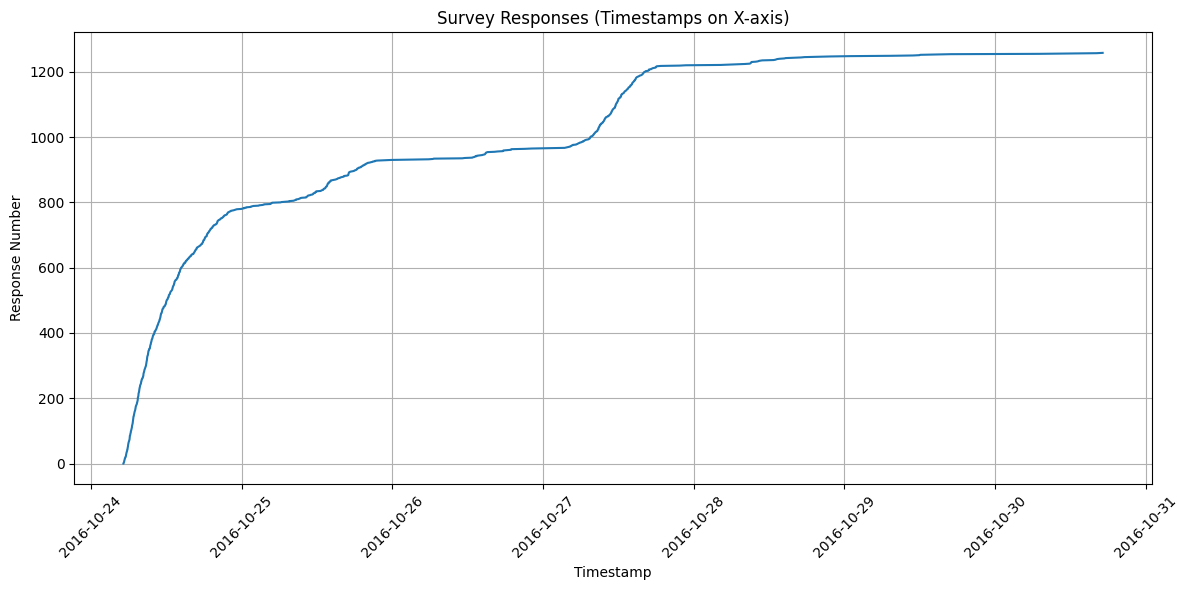

In [39]:
import matplotlib.pyplot as plt

# Create a Series with timestamp as index
ts = pd.Series(1, index=dtcandy_df["Timestamp"])

original_hourly = dtcandy_df["Timestamp"]

# Resample to hourly and count occurrences
hourly_counts = ts.resample('h').count()

# Plot
plt.figure(figsize=(12, 6))
plt.plot(original_hourly, range(len(original_hourly)))
plt.title('Survey Responses (Timestamps on X-axis)')
plt.xlabel('Timestamp')
plt.ylabel('Response Number')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The graph above plots the raw timestamp column "as is", plotting the rate survey responses over time. This tells us when each survey was submitted in chronological order. Naturally, the count of responses will increase as time increases - it has a linear relationship.

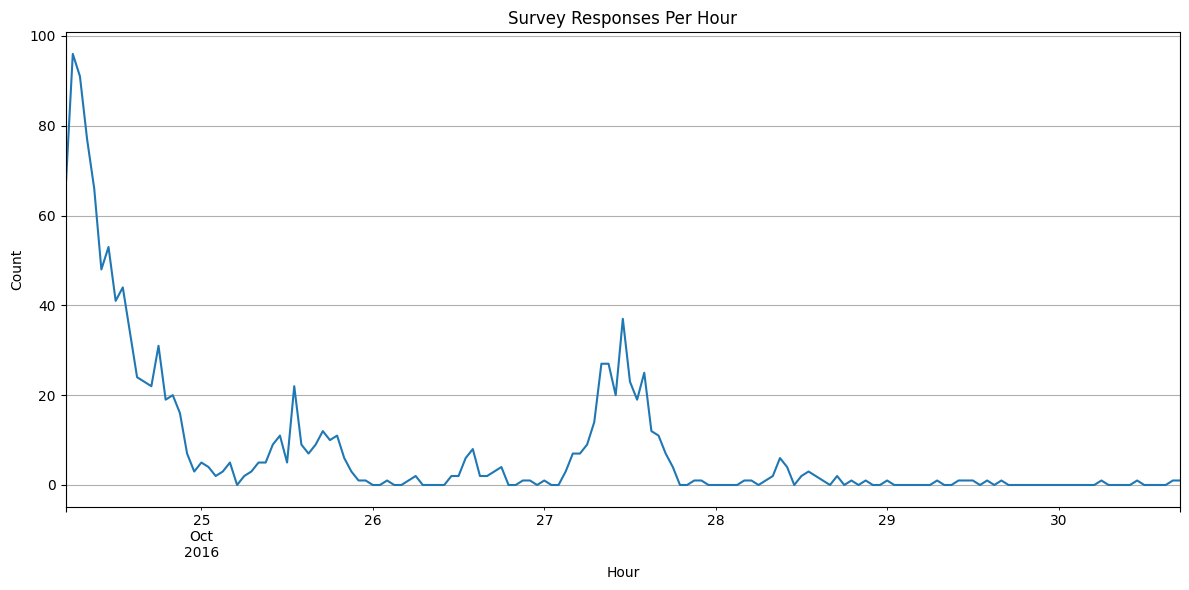

In [38]:
# Plot
hourly_counts.plot(kind='line', figsize=(12, 6))
plt.title('Survey Responses Per Hour')
plt.xlabel('Hour')
plt.ylabel('Count')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In this plot, the timestamps have been resampled into hourly buckets on the X axis, where Y is the count of resonses per hour. This shows how many surveys were submitted during each hour. We can see that there are pearks and valleys showing which hours has the most or least activity. In other words, this graph shows the distribution of responses by hour.